

 What Makes Customers Recommend Fashion Products?

## Data Science Analysis of Women's E-Commerce Clothing Reviews

**Research Question:**  
Which factors are most strongly associated with customers recommending clothing products?

**Dataset:**  
Women's E-Commerce Clothing Reviews

**Methods:**  
Exploratory Data Analysis, Statistical Testing, Logistic Regression, TF-IDF Text Analysis, and Model Evaluation



In [118]:
import pandas as pd

df = pd.read_csv("/content/Womens Clothing E-Commerce Reviews.csv")

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (23486, 11)


,Unnamed: 0,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
0,0,767,33,NaN,Absolutely wonderful - silky and sexy and comf...,4,1,0,Initmates,Intimate,Intimates
1,1,1080,34,NaN,Love this dress! it's sooo pretty. i happene...,5,1,4,General,Dresses,Dresses
2,2,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0,0,General,Dresses,Dresses
3,3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1,0,General Petite,Bottoms,Pants
4,4,847,47,Flattering shirt,This shirt is very flattering to all due to th...,5,1,6,General,Tops,Blouses


In [55]:

# Basic dataset overview

print("COLUMN NAMES:")
print(df.columns.tolist())

print("\nDATA TYPES:")
print(df.dtypes)

print("\nMISSING VALUES:")
print(df.isnull().sum())

print("\nTARGET VARIABLE DISTRIBUTION - Recommended IND:")
print(df["Recommended IND"].value_counts())

print("\nRECOMMENDATION PERCENTAGES:")
print(df["Recommended IND"].value_counts(normalize=True) * 100)

COLUMN NAMES:
['Unnamed: 0', 'Clothing ID', 'Age', 'Title', 'Review Text', 'Rating', 'Recommended IND', 'Positive Feedback Count', 'Division Name', 'Department Name', 'Class Name']

DATA TYPES:
Unnamed: 0                  int64
Clothing ID                 int64
Age                         int64
Title                      object
Review Text                object
Rating                      int64
Recommended IND             int64
Positive Feedback Count     int64
Division Name              object
Department Name            object
Class Name                 object
dtype: object

MISSING VALUES:
Unnamed: 0                    0
Clothing ID                   0
Age                           0
Title                      3810
Review Text                 845
Rating                        0
Recommended IND               0
Positive Feedback Count       0
Division Name                14
Department Name              14
Class Name                   14
dtype: int64

TARGET VARIABLE DISTRIBUTION - Reco

In [56]:
# Descriptive statistics for numerical variables

df.describe()

,Unnamed: 0,Clothing ID,Age,Rating,Recommended IND,Positive Feedback Count
count,23486.000000,23486.000000,23486.000000,23486.000000,23486.000000,23486.000000
mean,11742.500000,918.118709,43.198544,4.196032,0.822362,2.535936
std,6779.968547,203.298980,12.279544,1.110031,0.382216,5.702202
min,0.000000,0.000000,18.000000,1.000000,0.000000,0.000000
25%,5871.250000,861.000000,34.000000,4.000000,1.000000,0.000000
50%,11742.500000,936.000000,41.000000,5.000000,1.000000,1.000000
75%,17613.750000,1078.000000,52.000000,5.000000,1.000000,3.000000
max,23485.000000,1205.000000,99.000000,5.000000,1.000000,122.000000


In [57]:


print("Division Name:")
print(df["Division Name"].value_counts(dropna=False))

print("\nDepartment Name:")
print(df["Department Name"].value_counts(dropna=False))

print("\nClass Name:")
print(df["Class Name"].value_counts(dropna=False))

Division Name:
Division Name
General           13850
General Petite     8120
Initmates          1502
NaN                  14
Name: count, dtype: int64

Department Name:
Department Name
Tops        10468
Dresses      6319
Bottoms      3799
Intimate     1735
Jackets      1032
Trend         119
NaN            14
Name: count, dtype: int64

Class Name:
Class Name
Dresses           6319
Knits             4843
Blouses           3097
Sweaters          1428
Pants             1388
Jeans             1147
Fine gauge        1100
Skirts             945
Jackets            704
Lounge             691
Swim               350
Outerwear          328
Shorts             317
Sleep              228
Legwear            165
Intimates          154
Layering           146
Trend              119
NaN                 14
Casual bottoms       2
Chemises             1
Name: count, dtype: int64


In [58]:


print("Rating distribution:")
print(df["Rating"].value_counts().sort_index())

print("\nRating percentages:")
print(df["Rating"].value_counts(normalize=True).sort_index() * 100)

Rating distribution:
Rating
1      842
2     1565
3     2871
4     5077
5    13131
Name: count, dtype: int64

Rating percentages:
Rating
1     3.585115
2     6.663544
3    12.224304
4    21.617134
5    55.909904
Name: proportion, dtype: float64


In [59]:


rating_recommendation = pd.crosstab(
    df["Rating"],
    df["Recommended IND"],
    normalize="index"
) * 100

rating_recommendation

Recommended IND,0,1
Rating,,
1,98.099762,1.900238
2,93.993610,6.006390
3,58.585859,41.414141
4,3.309041,96.690959
5,0.190389,99.809611


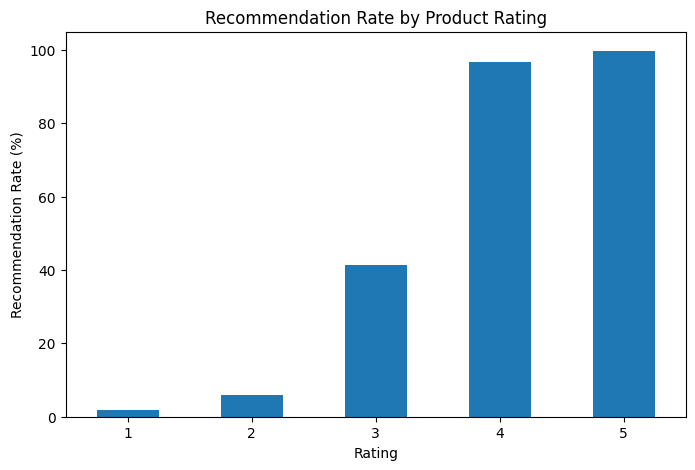

In [60]:
import matplotlib.pyplot as plt


recommendation_by_rating = df.groupby("Rating")["Recommended IND"].mean() * 100


plt.figure(figsize=(8, 5))
recommendation_by_rating.plot(kind="bar")

plt.title("Recommendation Rate by Product Rating")
plt.xlabel("Rating")
plt.ylabel("Recommendation Rate (%)")
plt.xticks(rotation=0)
plt.ylim(0, 105)

plt.show()

In [61]:


df["Age Group"] = pd.cut(
    df["Age"],
    bins=[17, 25, 35, 45, 55, 65, 100],
    labels=["18-25", "26-35", "36-45", "46-55", "56-65", "66+"]
)



recommendation_by_age = (
    df.groupby("Age Group", observed=False)["Recommended IND"].mean() * 100
)

print("Recommendation rate by age group:")
print(recommendation_by_age)

Recommendation rate by age group:
Age Group
18-25    85.118561
26-35    79.888754
36-45    82.072791
46-55    82.155225
56-65    85.147541
66+      84.568966
Name: Recommended IND, dtype: float64


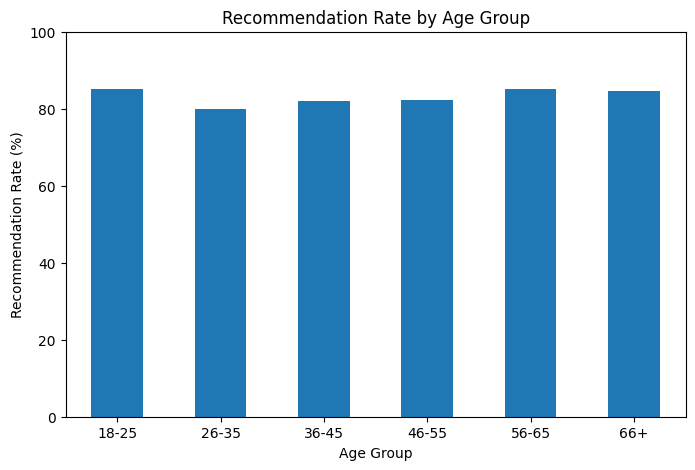

In [62]:
import matplotlib.pyplot as plt


plt.figure(figsize=(8, 5))
recommendation_by_age.plot(kind="bar")

plt.title("Recommendation Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Recommendation Rate (%)")
plt.xticks(rotation=0)
plt.ylim(0, 100)

plt.show()

In [63]:


recommendation_by_department = (
    df.groupby("Department Name")["Recommended IND"].mean() * 100
)

print("Recommendation rate by department:")
print(recommendation_by_department.sort_values(ascending=False))

Recommendation rate by department:
Department Name
Bottoms     85.127665
Intimate    85.014409
Jackets     83.624031
Tops        81.515094
Dresses     80.819750
Trend       73.949580
Name: Recommended IND, dtype: float64


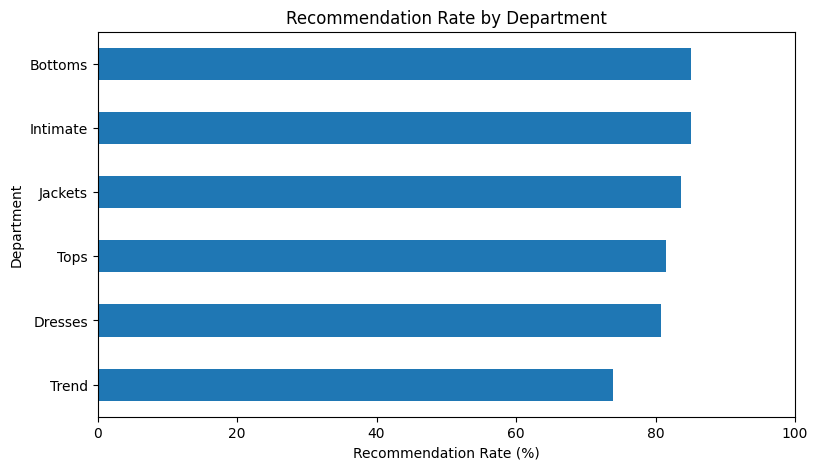

In [64]:


plt.figure(figsize=(9, 5))
recommendation_by_department.sort_values().plot(kind="barh")

plt.title("Recommendation Rate by Department")
plt.xlabel("Recommendation Rate (%)")
plt.ylabel("Department")
plt.xlim(0, 100)

plt.show()

In [65]:


recommendation_by_class = (
    df.groupby("Class Name")["Recommended IND"].agg(["mean", "count"])
)

recommendation_by_class["mean"] = recommendation_by_class["mean"] * 100

recommendation_by_class = recommendation_by_class.sort_values(
    "mean",
    ascending=False
)

print("Recommendation rate and review count by product class:")
print(recommendation_by_class)

Recommendation rate and review count by product class:
                      mean  count
Class Name                       
Casual bottoms  100.000000      2
Chemises        100.000000      1
Layering         88.356164    146
Jeans            88.142982   1147
Legwear          86.060606    165
Lounge           85.962373    691
Intimates        85.714286    154
Sleep            85.526316    228
Skirts           84.550265    945
Jackets          84.517045    704
Shorts           83.911672    317
Fine gauge       83.727273   1100
Pants            83.285303   1388
Knits            81.767499   4843
Outerwear        81.707317    328
Blouses          81.013884   3097
Dresses          80.819750   6319
Swim             80.571429    350
Sweaters         80.042017   1428
Trend            73.949580    119


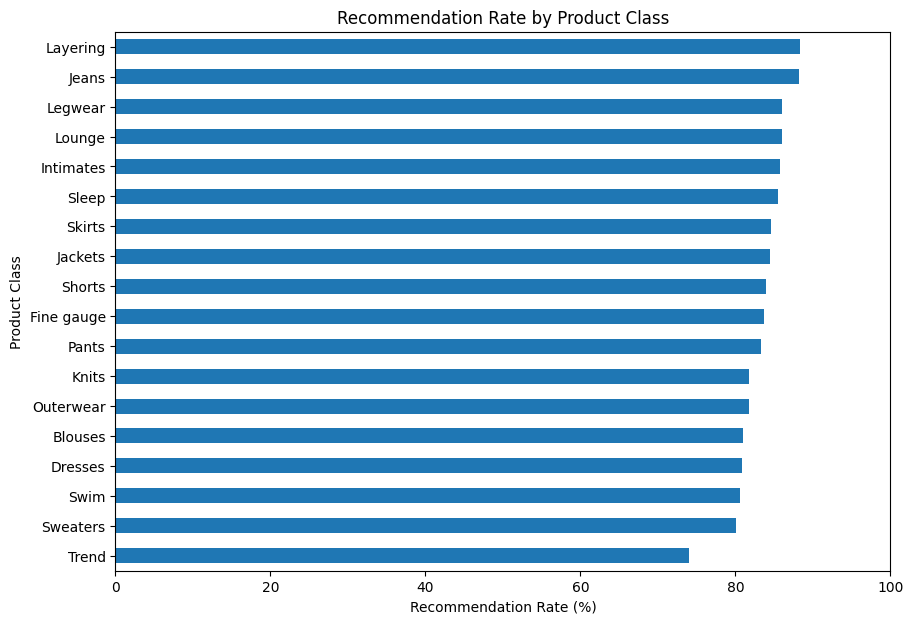

In [66]:


class_analysis = recommendation_by_class[
    recommendation_by_class["count"] >= 100
].sort_values("mean")

plt.figure(figsize=(10, 7))
class_analysis["mean"].plot(kind="barh")

plt.title("Recommendation Rate by Product Class")
plt.xlabel("Recommendation Rate (%)")
plt.ylabel("Product Class")
plt.xlim(0, 100)

plt.show()

In [67]:


feedback_by_recommendation = (
    df.groupby("Recommended IND")["Positive Feedback Count"]
    .agg(["mean", "median", "count"])
)

feedback_by_recommendation

,mean,median,count
Recommended IND,,,
0,3.383030,1.0,4172
1,2.352956,1.0,19314


In [68]:


print("Total reviews:", len(df))
print("Missing review texts:", df["Review Text"].isna().sum())
print(
    "Available review texts:",
    df["Review Text"].notna().sum()
)

print("\nSample review texts:")
print(df["Review Text"].dropna().head(5).to_string(index=False))

Total reviews: 23486
Missing review texts: 845
Available review texts: 22641

Sample review texts:
Absolutely wonderful - silky and sexy and comfo...
Love this dress!  it's sooo pretty.  i happened...
I had such high hopes for this dress and really...
I love, love, love this jumpsuit. it's fun, fli...
This shirt is very flattering to all due to the...


In [69]:


df["Review Length"] = df["Review Text"].fillna("").str.len()


review_length_by_recommendation = (
    df.groupby("Recommended IND")["Review Length"]
    .agg(["mean", "median", "min", "max", "count"])
)

print("Review length by recommendation status:")
print(review_length_by_recommendation)

Review length by recommendation status:
                       mean  median  min  max  count
Recommended IND                                     
0                312.916587   312.0    0  508   4172
1                294.269183   288.0    0  508  19314


In [70]:


df["Word Count"] = df["Review Text"].fillna("").str.split().str.len()


word_count_by_recommendation = (
    df.groupby("Recommended IND")["Word Count"]
    .agg(["mean", "median", "min", "max", "count"])
)

print("Word count by recommendation status:")
print(word_count_by_recommendation)

Word count by recommendation status:
                      mean  median  min  max  count
Recommended IND                                    
0                60.946788    60.0    0  115   4172
1                57.401004    56.0    0  115  19314


In [71]:
from collections import Counter
import re

recommended_reviews = df.loc[
    df["Recommended IND"] == 1, "Review Text"
].dropna()

not_recommended_reviews = df.loc[
    df["Recommended IND"] == 0, "Review Text"
].dropna()


recommended_text = " ".join(recommended_reviews).lower()
not_recommended_text = " ".join(not_recommended_reviews).lower()

recommended_words = re.findall(r"\b[a-z]+\b", recommended_text)
not_recommended_words = re.findall(r"\b[a-z]+\b", not_recommended_text)


stopwords = {
    "the", "and", "to", "of", "a", "in", "is", "for", "on",
    "that", "this", "it", "with", "my", "was", "but", "i",
    "have", "had", "very", "so", "as", "are", "be", "not",
    "would", "me", "they", "their", "at", "or", "from", "one",
    "all", "just", "really", "about", "do", "like", "you",
    "dress", "wear", "size"
}


recommended_word_counts = Counter(
    word for word in recommended_words
    if word not in stopwords
)

not_recommended_word_counts = Counter(
    word for word in not_recommended_words
    if word not in stopwords
)

print("Most common words in recommended reviews:")
print(recommended_word_counts.most_common(20))

print("\nMost common words in non-recommended reviews:")
print(not_recommended_word_counts.most_common(20))

Most common words in recommended reviews:
[('love', 8023), ('s', 7452), ('t', 6806), ('fit', 5998), ('top', 5846), ('m', 5698), ('great', 5587), ('am', 4852), ('too', 4603), ('up', 4151), ('color', 3888), ('small', 3819), ('can', 3664), ('perfect', 3574), ('fabric', 3553), ('little', 3412), ('more', 3308), ('will', 3132), ('these', 3095), ('if', 3076)]

Most common words in non-recommended reviews:
[('t', 2049), ('top', 1572), ('too', 1455), ('s', 1427), ('fit', 1327), ('fabric', 1245), ('back', 1039), ('m', 1022), ('look', 965), ('love', 928), ('small', 910), ('am', 895), ('if', 893), ('ordered', 825), ('when', 755), ('material', 736), ('much', 721), ('color', 717), ('out', 699), ('up', 698)]


In [72]:

additional_stopwords = {
    "too", "up", "down", "out", "can", "will", "more",
    "little", "much", "when", "if", "am", "one", "all",
    "just", "really", "like", "would", "could", "also",
    "get", "got", "go", "goes", "make", "made", "know",
    "still", "even", "well", "back"
}


recommended_word_counts_clean = Counter(
    word for word in recommended_words
    if len(word) > 1
    and word not in stopwords
    and word not in additional_stopwords
)

not_recommended_word_counts_clean = Counter(
    word for word in not_recommended_words
    if len(word) > 1
    and word not in stopwords
    and word not in additional_stopwords
)

print("Most common meaningful words in recommended reviews:")
print(recommended_word_counts_clean.most_common(20))

print("\nMost common meaningful words in non-recommended reviews:")
print(not_recommended_word_counts_clean.most_common(20))

Most common meaningful words in recommended reviews:
[('love', 8023), ('fit', 5998), ('top', 5846), ('great', 5587), ('color', 3888), ('small', 3819), ('perfect', 3574), ('fabric', 3553), ('these', 3095), ('look', 3074), ('flattering', 3065), ('soft', 3048), ('ordered', 3025), ('comfortable', 2888), ('an', 2697), ('fits', 2685), ('bought', 2684), ('nice', 2610), ('bit', 2557), ('because', 2538)]

Most common meaningful words in non-recommended reviews:
[('top', 1572), ('fit', 1327), ('fabric', 1245), ('look', 965), ('love', 928), ('small', 910), ('ordered', 825), ('material', 736), ('color', 717), ('shirt', 687), ('an', 673), ('way', 645), ('because', 635), ('looks', 622), ('were', 601), ('than', 593), ('looked', 589), ('didn', 564), ('quality', 559), ('there', 553)]


In [73]:


recommended_total_words = sum(recommended_word_counts_clean.values())
not_recommended_total_words = sum(not_recommended_word_counts_clean.values())

word_comparison = []

for word in set(recommended_word_counts_clean) | set(not_recommended_word_counts_clean):
    recommended_frequency = (
        recommended_word_counts_clean[word] / recommended_total_words * 100000
    )

    not_recommended_frequency = (
        not_recommended_word_counts_clean[word] / not_recommended_total_words * 100000
    )

    word_comparison.append(
        (
            word,
            recommended_frequency,
            not_recommended_frequency
        )
    )

word_comparison_df = pd.DataFrame(
    word_comparison,
    columns=[
        "Word",
        "Recommended Frequency",
        "Non-Recommended Frequency"
    ]
)


word_comparison_df["Difference"] = (
    word_comparison_df["Recommended Frequency"]
    - word_comparison_df["Non-Recommended Frequency"]
)

print("Words relatively more common in recommended reviews:")
print(
    word_comparison_df
    .sort_values("Difference", ascending=False)
    .head(20)
)

print("\nWords relatively more common in non-recommended reviews:")
print(
    word_comparison_df
    .sort_values("Difference", ascending=True)
    .head(20)
)

Words relatively more common in recommended reviews:
              Word  Recommended Frequency  Non-Recommended Frequency  \
12725         love            1561.186525                 795.931145   
4871         great            1087.168031                 454.572745   
9903       perfect             695.460631                 171.536885   
9326   comfortable             561.972664                 147.521721   
3134          fits             522.471123                 145.806352   
1083          soft             593.106884                 253.016905   
5764         jeans             435.489897                 140.660245   
10056       bought             522.276534                 259.020696   
636            bit             497.563747                 265.024487   
8920    flattering             596.414895                 389.388728   
11689    perfectly             263.862511                  64.326332   
8862        summer             279.235032                  99.491393   
13355  comp

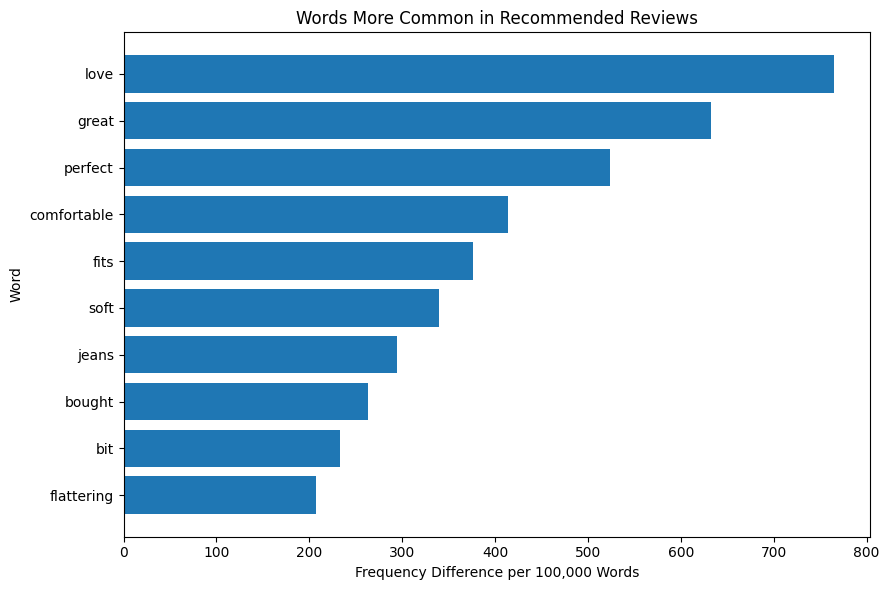

In [74]:


plt.figure(figsize=(9, 6))

plt.barh(
    top_recommended_words["Word"],
    top_recommended_words["Difference"]
)

plt.title("Words More Common in Recommended Reviews")
plt.xlabel("Frequency Difference per 100,000 Words")
plt.ylabel("Word")

plt.tight_layout()
plt.show()

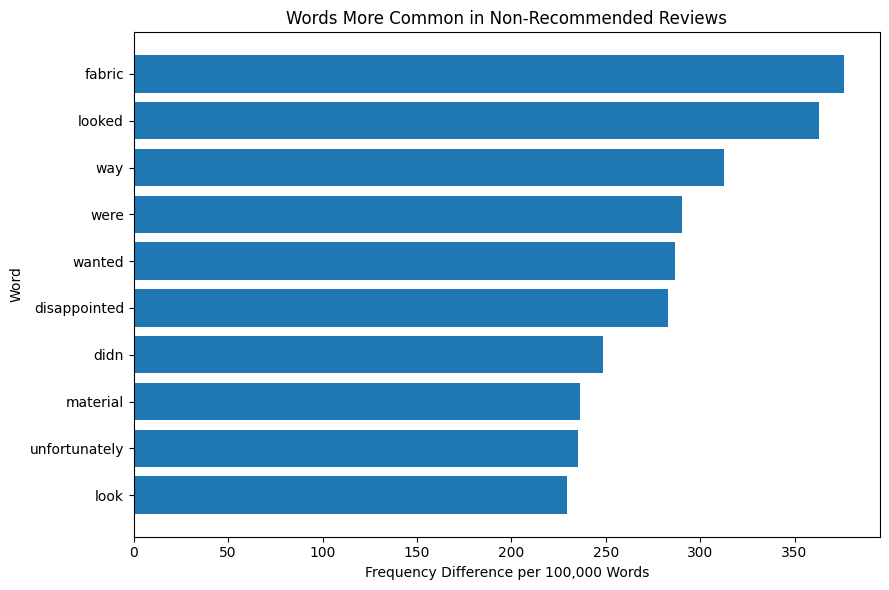

In [75]:


plt.figure(figsize=(9, 6))

plt.barh(
    top_not_recommended_words["Word"],
    top_not_recommended_words["Difference"].abs()
)

plt.title("Words More Common in Non-Recommended Reviews")
plt.xlabel("Frequency Difference per 100,000 Words")
plt.ylabel("Word")

plt.tight_layout()
plt.show()

In [76]:
from scipy.stats import chi2_contingency


rating_recommendation_table = pd.crosstab(
    df["Rating"],
    df["Recommended IND"]
)


chi2, p_value, degrees_of_freedom, expected = chi2_contingency(
    rating_recommendation_table
)

print("Chi-square statistic:", chi2)
print("p-value:", p_value)
print("Degrees of freedom:", degrees_of_freedom)

Chi-square statistic: 16722.503172306744
p-value: 0.0
Degrees of freedom: 4


In [77]:
from scipy.stats import chi2_contingency


age_recommendation_table = pd.crosstab(
    df["Age Group"],
    df["Recommended IND"]
)


chi2_age, p_value_age, degrees_of_freedom_age, expected_age = chi2_contingency(
    age_recommendation_table
)

print("Chi-square statistic:", chi2_age)
print("p-value:", p_value_age)
print("Degrees of freedom:", degrees_of_freedom_age)

Chi-square statistic: 50.83163562294416
p-value: 9.363560519511942e-10
Degrees of freedom: 5


In [78]:
from scipy.stats import chi2_contingency


department_recommendation_table = pd.crosstab(
    df["Department Name"],
    df["Recommended IND"]
)


chi2_department, p_value_department, degrees_of_freedom_department, expected_department = chi2_contingency(
    department_recommendation_table
)

print("Chi-square statistic:", chi2_department)
print("p-value:", p_value_department)
print("Degrees of freedom:", degrees_of_freedom_department)

Chi-square statistic: 50.243426369384586
p-value: 1.2356077447849029e-09
Degrees of freedom: 5


In [79]:
from scipy.stats import chi2_contingency
import numpy as np


rating_recommendation_table = pd.crosstab(
    df["Rating"],
    df["Recommended IND"]
)


chi2, p_value, degrees_of_freedom, expected = chi2_contingency(
    rating_recommendation_table
)


n = rating_recommendation_table.sum().sum()
min_dimension = min(
    rating_recommendation_table.shape[0] - 1,
    rating_recommendation_table.shape[1] - 1
)

cramers_v = np.sqrt(
    chi2 / (n * min_dimension)
)

print("Cramér's V:", cramers_v)

Cramér's V: 0.8438128120840108


In [80]:

age_recommendation_table = pd.crosstab(
    df["Age Group"],
    df["Recommended IND"]
)


chi2_age, p_value_age, degrees_of_freedom_age, expected_age = chi2_contingency(
    age_recommendation_table
)


n_age = age_recommendation_table.sum().sum()
min_dimension_age = min(
    age_recommendation_table.shape[0] - 1,
    age_recommendation_table.shape[1] - 1
)

cramers_v_age = np.sqrt(
    chi2_age / (n_age * min_dimension_age)
)

print("Cramér's V for Age Group:", cramers_v_age)

Cramér's V for Age Group: 0.04652244315449381


In [81]:

department_recommendation_table = pd.crosstab(
    df["Department Name"],
    df["Recommended IND"]
)


chi2_department, p_value_department, degrees_of_freedom_department, expected_department = chi2_contingency(
    department_recommendation_table
)


n_department = department_recommendation_table.sum().sum()
min_dimension_department = min(
    department_recommendation_table.shape[0] - 1,
    department_recommendation_table.shape[1] - 1
)

cramers_v_department = np.sqrt(
    chi2_department / (n_department * min_dimension_department)
)

print("Cramér's V for Department:", cramers_v_department)

Cramér's V for Department: 0.04626627938469459


In [82]:
from scipy.stats import mannwhitneyu


recommended_feedback = df.loc[
    df["Recommended IND"] == 1,
    "Positive Feedback Count"
]

not_recommended_feedback = df.loc[
    df["Recommended IND"] == 0,
    "Positive Feedback Count"
]


u_statistic, p_value_feedback = mannwhitneyu(
    recommended_feedback,
    not_recommended_feedback,
    alternative="two-sided"
)

print("Mann-Whitney U statistic:", u_statistic)
print("p-value:", p_value_feedback)

Mann-Whitney U statistic: 35656691.0
p-value: 2.878791786554493e-35


In [83]:
from scipy.stats import mannwhitneyu


recommended_length = df.loc[
    df["Recommended IND"] == 1,
    "Review Length"
]

not_recommended_length = df.loc[
    df["Recommended IND"] == 0,
    "Review Length"
]


u_statistic_length, p_value_length = mannwhitneyu(
    recommended_length,
    not_recommended_length,
    alternative="two-sided"
)

print("Mann-Whitney U statistic:", u_statistic_length)
print("p-value:", p_value_length)

Mann-Whitney U statistic: 37605442.0
p-value: 1.3309788004413205e-11


In [84]:


statistical_results = pd.DataFrame({
    "Analysis": [
        "Rating vs Recommendation",
        "Age Group vs Recommendation",
        "Department vs Recommendation",
        "Positive Feedback Count vs Recommendation",
        "Review Length vs Recommendation"
    ],
    "Test": [
        "Chi-square",
        "Chi-square",
        "Chi-square",
        "Mann-Whitney U",
        "Mann-Whitney U"
    ],
    "Statistic": [
        chi2,
        chi2_age,
        chi2_department,
        u_statistic,
        u_statistic_length
    ],
    "p-value": [
        p_value,
        p_value_age,
        p_value_department,
        p_value_feedback,
        p_value_length
    ],
    "Effect Size": [
        cramers_v,
        cramers_v_age,
        cramers_v_department,
        "Not calculated",
        "Not calculated"
    ]
})

statistical_results

,Analysis,Test,Statistic,p-value,Effect Size
0,Rating vs Recommendation,Chi-square,1.672250e+04,0.000000e+00,0.843813
1,Age Group vs Recommendation,Chi-square,5.083164e+01,9.363561e-10,0.046522
2,Department vs Recommendation,Chi-square,5.024343e+01,1.235608e-09,0.046266
3,Positive Feedback Count vs Recommendation,Mann-Whitney U,3.565669e+07,2.878792e-35,Not calculated
4,Review Length vs Recommendation,Mann-Whitney U,3.760544e+07,1.330979e-11,Not calculated


In [85]:

df = df.drop(columns=["Unnamed: 0"])

print("Dataset shape after removing the index column:", df.shape)
print("\nRemaining columns:")
print(df.columns.tolist())

Dataset shape after removing the index column: (23486, 13)

Remaining columns:
['Clothing ID', 'Age', 'Title', 'Review Text', 'Rating', 'Recommended IND', 'Positive Feedback Count', 'Division Name', 'Department Name', 'Class Name', 'Age Group', 'Review Length', 'Word Count']


In [86]:

missing_values = df.isnull().sum()

print("Missing values by column:")
print(missing_values)

Missing values by column:
Clothing ID                   0
Age                           0
Title                      3810
Review Text                 845
Rating                        0
Recommended IND               0
Positive Feedback Count       0
Division Name                14
Department Name              14
Class Name                   14
Age Group                     0
Review Length                 0
Word Count                    0
dtype: int64


In [87]:

missing_categories = df[
    df["Division Name"].isnull()
    | df["Department Name"].isnull()
    | df["Class Name"].isnull()
]

print("Number of rows with missing category information:", len(missing_categories))

missing_categories

Number of rows with missing category information: 14


,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name,Age Group,Review Length,Word Count
9444,72,25,My favorite socks!!!,"I never write reviews, but these socks are so ...",5,1,0,NaN,NaN,NaN,18-25,308,56
13767,492,23,So soft!,I just love this hoodie! it is so soft and com...,5,1,1,NaN,NaN,NaN,18-25,241,53
13768,492,49,Wardrobe staple,Love this hoodie. so soft and goes with everyt...,5,1,0,NaN,NaN,NaN,46-55,106,17
13787,492,48,NaN,NaN,5,1,0,NaN,NaN,NaN,46-55,0,0
16216,152,36,Warm and cozy,"Just what i was looking for. soft, cozy and warm.",5,1,0,NaN,NaN,NaN,36-45,49,10
16221,152,37,Love!,I am loving these. they are quite long but are...,5,1,0,NaN,NaN,NaN,36-45,110,22
16223,152,39,"""long and warm""",These leg warmers are perfect for me. they are...,5,1,0,NaN,NaN,NaN,36-45,162,30
18626,184,34,Nubby footless tights,"These are amazing quality. i agree, size up to...",5,1,5,NaN,NaN,NaN,26-35,275,54
18671,184,54,New workhorse,These tights are amazing! if i care for them w...,5,1,0,NaN,NaN,NaN,46-55,97,19
20088,772,50,Comfy sweatshirt!,This sweatshirt is really nice! it's oversize...,5,1,0,NaN,NaN,NaN,46-55,256,44


In [88]:

missing_ids = df.loc[
    df["Division Name"].isnull(),
    "Clothing ID"
].unique()

category_lookup = (
    df[df["Clothing ID"].isin(missing_ids)]
    .groupby("Clothing ID")[["Division Name", "Department Name", "Class Name"]]
    .first()
)

print("Category information available for the affected Clothing IDs:")
print(category_lookup)

Category information available for the affected Clothing IDs:
            Division Name Department Name Class Name
Clothing ID                                         
72                   None            None       None
136                  None            None       None
152                  None            None       None
184                  None            None       None
492                  None            None       None
665                  None            None       None
772                  None            None       None


In [89]:

duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 21


In [90]:

duplicate_rows = df[df.duplicated(keep=False)]

print("Number of rows involved in duplicates:", len(duplicate_rows))

duplicate_rows.sort_values(
    by=["Clothing ID", "Age", "Rating"]
).head(30)

Number of rows involved in duplicates: 42


,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name,Age Group,Review Length,Word Count
9671,828,46,NaN,NaN,5,1,0,General Petite,Tops,Blouses,46-55,0,0
18747,828,46,NaN,NaN,5,1,0,General Petite,Tops,Blouses,46-55,0,0
2941,829,66,NaN,NaN,5,1,0,General Petite,Tops,Blouses,66+,0,0
4850,829,66,NaN,NaN,5,1,0,General Petite,Tops,Blouses,66+,0,0
4866,834,70,NaN,NaN,5,1,0,General Petite,Tops,Blouses,66+,0,0
9306,834,70,NaN,NaN,5,1,0,General Petite,Tops,Blouses,66+,0,0
13236,850,37,NaN,NaN,5,1,0,General,Tops,Blouses,36-45,0,0
17256,850,37,NaN,NaN,5,1,0,General,Tops,Blouses,36-45,0,0
5536,861,34,NaN,NaN,5,1,0,General,Tops,Knits,26-35,0,0
5671,861,34,NaN,NaN,5,1,0,General,Tops,Knits,26-35,0,0


In [91]:

df = df.drop_duplicates().reset_index(drop=True)

print("Dataset shape after removing duplicates:", df.shape)
print("Remaining duplicate rows:", df.duplicated().sum())

Dataset shape after removing duplicates: (23465, 13)
Remaining duplicate rows: 0


In [92]:


print("Division Name:")
print(df["Division Name"].value_counts(dropna=False))

print("\nDepartment Name:")
print(df["Department Name"].value_counts(dropna=False))

print("\nClass Name:")
print(df["Class Name"].value_counts(dropna=False))

Division Name:
Division Name
General           13839
General Petite     8110
Initmates          1502
NaN                  14
Name: count, dtype: int64

Department Name:
Department Name
Tops        10455
Dresses      6312
Bottoms      3798
Intimate     1735
Jackets      1032
Trend         119
NaN            14
Name: count, dtype: int64

Class Name:
Class Name
Dresses           6312
Knits             4835
Blouses           3093
Sweaters          1428
Pants             1388
Jeans             1146
Fine gauge        1099
Skirts             945
Jackets            704
Lounge             691
Swim               350
Outerwear          328
Shorts             317
Sleep              228
Legwear            165
Intimates          154
Layering           146
Trend              119
NaN                 14
Casual bottoms       2
Chemises             1
Name: count, dtype: int64


In [93]:

print("Dataset shape:", df.shape)

print("\nMissing values in key variables:")
print(
    df[
        [
            "Age",
            "Rating",
            "Recommended IND",
            "Positive Feedback Count",
            "Division Name",
            "Department Name",
            "Class Name"
        ]
    ].isnull().sum()
)

print("\nDuplicate rows:", df.duplicated().sum())

Dataset shape: (23465, 13)

Missing values in key variables:
Age                         0
Rating                      0
Recommended IND             0
Positive Feedback Count     0
Division Name              14
Department Name            14
Class Name                 14
dtype: int64

Duplicate rows: 0


In [94]:


correlation_columns = [
    "Age",
    "Rating",
    "Recommended IND",
    "Positive Feedback Count",
    "Review Length",
    "Word Count"
]

correlation_matrix = df[correlation_columns].corr()

print("Correlation matrix:")
correlation_matrix

Correlation matrix:


,Age,Rating,Recommended IND,Positive Feedback Count,Review Length,Word Count
Age,1.000000,0.026914,0.030696,0.043040,0.026461,0.024864
Rating,0.026914,1.000000,0.792307,-0.064710,-0.072276,-0.073395
Recommended IND,0.030696,0.792307,1.000000,-0.068873,-0.046010,-0.044213
Positive Feedback Count,0.043040,-0.064710,-0.068873,1.000000,0.208430,0.205187
Review Length,0.026461,-0.072276,-0.046010,0.208430,1.000000,0.992677
Word Count,0.024864,-0.073395,-0.044213,0.205187,0.992677,1.000000


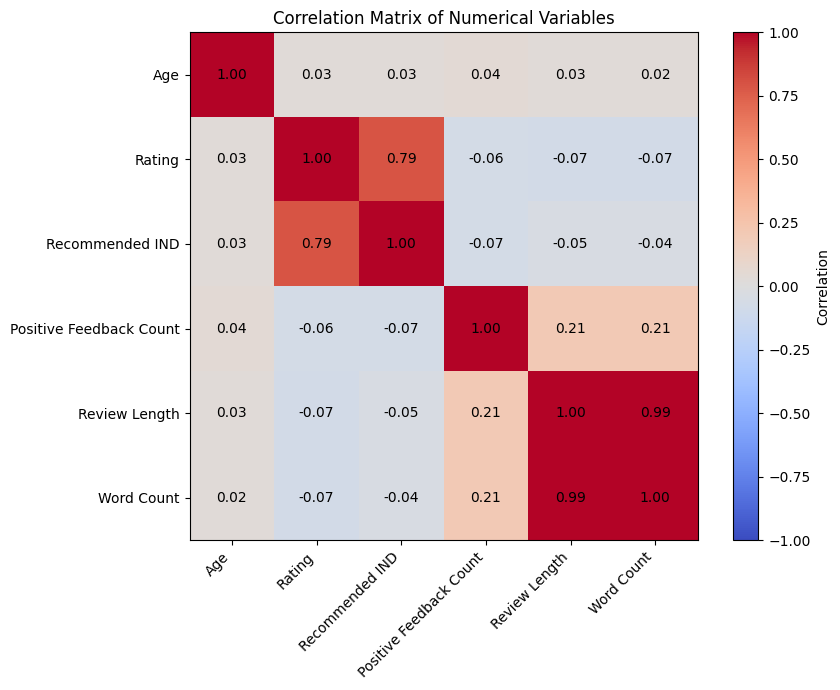

In [95]:
import matplotlib.pyplot as plt


plt.figure(figsize=(9, 7))

plt.imshow(correlation_matrix, cmap="coolwarm", vmin=-1, vmax=1)

plt.colorbar(label="Correlation")

plt.xticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns
)


for i in range(len(correlation_matrix.columns)):
    for j in range(len(correlation_matrix.columns)):
        plt.text(
            j,
            i,
            f"{correlation_matrix.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )

plt.title("Correlation Matrix of Numerical Variables")
plt.tight_layout()
plt.show()

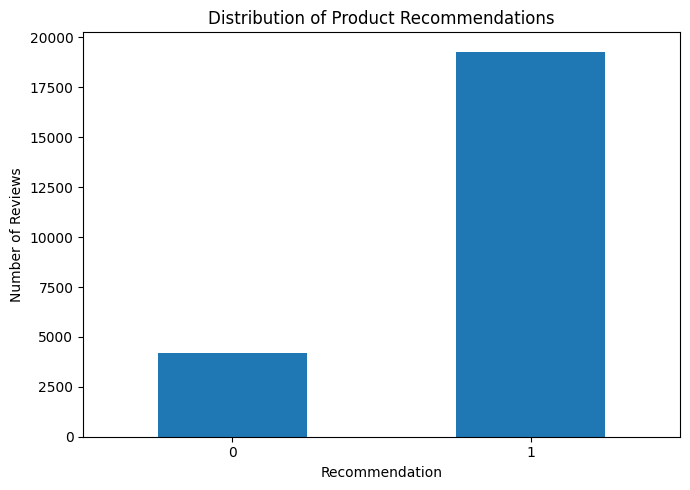

In [96]:
import matplotlib.pyplot as plt

recommendation_counts = df["Recommended IND"].value_counts().sort_index()

plt.figure(figsize=(7, 5))

recommendation_counts.plot(
    kind="bar",
    tick_label=["Not Recommended", "Recommended"]
)

plt.title("Distribution of Product Recommendations")
plt.xlabel("Recommendation")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [97]:
print("FINAL DATASET CHECK")
print("=" * 40)

print("Dataset shape:", df.shape)

print("\nRecommendation distribution:")
print(df["Recommended IND"].value_counts())

print("\nRecommendation percentages:")
print(
    (df["Recommended IND"].value_counts(normalize=True) * 100).round(2)
)

print("\nAverage rating:", round(df["Rating"].mean(), 2))
print("Average age:", round(df["Age"].mean(), 2))
print(
    "Average positive feedback count:",
    round(df["Positive Feedback Count"].mean(), 2)
)

print("\nMissing values in key variables:")
print(
    df[
        [
            "Age",
            "Rating",
            "Recommended IND",
            "Positive Feedback Count",
            "Review Text",
            "Division Name",
            "Department Name",
            "Class Name"
        ]
    ].isnull().sum()
)

print("\nDuplicate rows:", df.duplicated().sum())

FINAL DATASET CHECK
Dataset shape: (23465, 13)

Recommendation distribution:
Recommended IND
1    19293
0     4172
Name: count, dtype: int64

Recommendation percentages:
Recommended IND
1    82.22
0    17.78
Name: proportion, dtype: float64

Average rating: 4.2
Average age: 43.2
Average positive feedback count: 2.54

Missing values in key variables:
Age                          0
Rating                       0
Recommended IND              0
Positive Feedback Count      0
Review Text                825
Division Name               14
Department Name             14
Class Name                  14
dtype: int64

Duplicate rows: 0


Data Cleaning and Preparation

The dataset was cleaned by removing an unnecessary index column and 21 exact duplicate rows. Missing values in the review text and product category fields were retained because they do not affect the main numerical analyses. No values were artificially imputed. Additional variables, including age groups, review length, and word count, were created for further analysis.

In [98]:
cleaned_df = df.copy()

print("Cleaned dataset saved successfully.")
print("Shape:", cleaned_df.shape)

Cleaned dataset saved successfully.
Shape: (23465, 13)


In [99]:


ml_features = [
    "Age",
    "Positive Feedback Count",
    "Review Length",
    "Word Count"
]

print("Potential ML features:")
print(ml_features)

print("\nTarget variable:")
print("Recommended IND")

print("\nFeature data shape:", cleaned_df[ml_features].shape)
print("Target data shape:", cleaned_df["Recommended IND"].shape)

Potential ML features:
['Age', 'Positive Feedback Count', 'Review Length', 'Word Count']

Target variable:
Recommended IND

Feature data shape: (23465, 4)
Target data shape: (23465,)


In [100]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Select features and target
X = cleaned_df[
    [
        "Age",
        "Positive Feedback Count",
        "Review Length",
        "Word Count"
    ]
]

y = cleaned_df["Recommended IND"]


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model = LogisticRegression(random_state=42)

model.fit(X_train_scaled, y_train)


y_pred = model.predict(X_test_scaled)


accuracy = accuracy_score(y_test, y_pred)

print("Logistic Regression Accuracy:", round(accuracy, 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Logistic Regression Accuracy: 0.8216

Classification Report:
              precision    recall  f1-score   support

           0       0.20      0.00      0.00       834
           1       0.82      1.00      0.90      3859

    accuracy                           0.82      4693
   macro avg       0.51      0.50      0.45      4693
weighted avg       0.71      0.82      0.74      4693


Confusion Matrix:
[[   1  833]
 [   4 3855]]


In [101]:


balanced_model = LogisticRegression(
    random_state=42,
    class_weight="balanced"
)

balanced_model.fit(X_train_scaled, y_train)


balanced_y_pred = balanced_model.predict(X_test_scaled)


balanced_accuracy = accuracy_score(
    y_test,
    balanced_y_pred
)

print("Balanced Logistic Regression Accuracy:", round(balanced_accuracy, 4))

print("\nClassification Report:")
print(classification_report(y_test, balanced_y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, balanced_y_pred))

Balanced Logistic Regression Accuracy: 0.5881

Classification Report:
              precision    recall  f1-score   support

           0       0.21      0.48      0.29       834
           1       0.84      0.61      0.71      3859

    accuracy                           0.59      4693
   macro avg       0.53      0.55      0.50      4693
weighted avg       0.73      0.59      0.64      4693


Confusion Matrix:
[[ 400  434]
 [1499 2360]]


In [102]:


coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": balanced_model.coef_[0]
})

coefficients["Absolute Coefficient"] = coefficients["Coefficient"].abs()

coefficients = coefficients.sort_values(
    "Absolute Coefficient",
    ascending=False
)

print("Logistic Regression Feature Importance:")
coefficients

Logistic Regression Feature Importance:


,Feature,Coefficient,Absolute Coefficient
2,Review Length,-0.369009,0.369009
3,Word Count,0.280286,0.280286
1,Positive Feedback Count,-0.170633,0.170633
0,Age,0.095634,0.095634


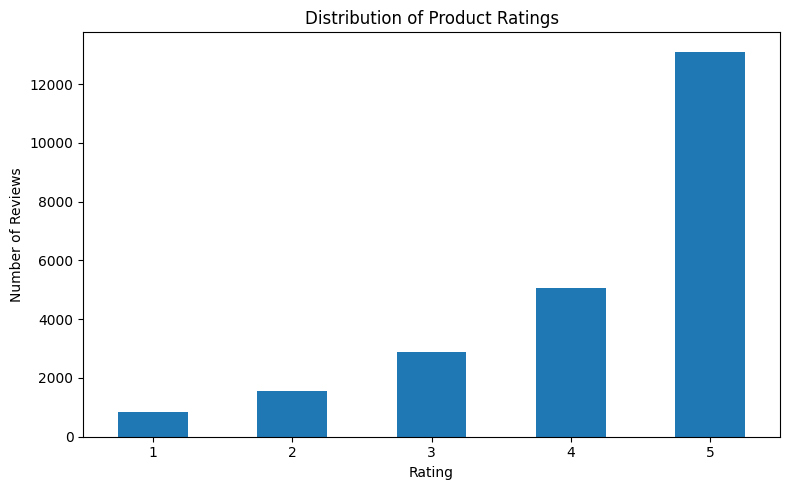

In [103]:
import matplotlib.pyplot as plt

rating_counts = df["Rating"].value_counts().sort_index()

plt.figure(figsize=(8, 5))
rating_counts.plot(kind="bar")

plt.title("Distribution of Product Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [104]:
import statsmodels.formula.api as smf


regression_df = cleaned_df[
    [
        "Recommended IND",
        "Age",
        "Positive Feedback Count",
        "Review Length",
        "Department Name"
    ]
].dropna()


logistic_model = smf.logit(
    formula="""
    Q('Recommended IND') ~ Age
    + Q('Positive Feedback Count')
    + Q('Review Length')
    + C(Q('Department Name'))
    """,
    data=regression_df
).fit()

print(logistic_model.summary())

Optimization terminated successfully.
         Current function value: 0.464068
         Iterations 6
                            Logit Regression Results                            
Dep. Variable:     Q('Recommended IND')   No. Observations:                23451
Model:                            Logit   Df Residuals:                    23442
Method:                             MLE   Df Model:                            8
Date:                  Sat, 07 Nov 2026   Pseudo R-squ.:                0.008823
Time:                          13:16:10   Log-Likelihood:                -10883.
converged:                         True   LL-Null:                       -10980.
Covariance Type:              nonrobust   LLR p-value:                 1.324e-37
                                          coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------
Intercept                               1.

In [105]:
import numpy as np


odds_ratios = pd.DataFrame({
    "Feature": logistic_model.params.index,
    "Odds Ratio": np.exp(logistic_model.params.values),
    "CI Lower": np.exp(logistic_model.conf_int()[0].values),
    "CI Upper": np.exp(logistic_model.conf_int()[1].values),
    "p-value": logistic_model.pvalues.values
})

odds_ratios = odds_ratios.round(4)

print("Odds Ratios and 95% Confidence Intervals:")
odds_ratios

Odds Ratios and 95% Confidence Intervals:


,Feature,Odds Ratio,CI Lower,CI Upper,p-value
0,Intercept,5.2427,4.4558,6.1686,0.0000
1,C(Q('Department Name'))[T.Dresses],0.7691,0.6892,0.8583,0.0000
2,C(Q('Department Name'))[T.Intimate],0.9813,0.8364,1.1514,0.8173
3,C(Q('Department Name'))[T.Jackets],0.9165,0.7591,1.1066,0.3646
4,C(Q('Department Name'))[T.Tops],0.7604,0.6863,0.8425,0.0000
5,C(Q('Department Name'))[T.Trend],0.5202,0.3417,0.7920,0.0023
6,Age,1.0077,1.0049,1.0105,0.0000
7,Q('Positive Feedback Count'),0.9780,0.9729,0.9830,0.0000
8,Q('Review Length'),0.9994,0.9992,0.9996,0.0000


In [107]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)


text_df = cleaned_df[
    ["Review Text", "Recommended IND"]
].dropna()

X_text = text_df["Review Text"]
y_text = text_df["Recommended IND"]


X_train_text, X_test_text, y_train_text, y_test_text = train_test_split(
    X_text,
    y_text,
    test_size=0.2,
    random_state=42,
    stratify=y_text
)

tfidf = TfidfVectorizer(
    max_features=5000,
    stop_words="english",
    ngram_range=(1, 2),
    min_df=3
)

X_train_tfidf = tfidf.fit_transform(X_train_text)
X_test_tfidf = tfidf.transform(X_test_text)

print("Training matrix shape:", X_train_tfidf.shape)
print("Testing matrix shape:", X_test_tfidf.shape)

Training matrix shape: (18112, 5000)
Testing matrix shape: (4528, 5000)


In [108]:
# Train Logistic Regression on TF-IDF features
text_model = LogisticRegression(
    class_weight="balanced",
    random_state=42,
    max_iter=1000
)

text_model.fit(X_train_tfidf, y_train_text)

# Make predictions
y_pred_text = text_model.predict(X_test_tfidf)

# Calculate evaluation metrics
text_accuracy = accuracy_score(y_test_text, y_pred_text)
text_auc = roc_auc_score(
    y_test_text,
    text_model.predict_proba(X_test_tfidf)[:, 1]
)

print("TF-IDF Logistic Regression Accuracy:", round(text_accuracy, 4))
print("TF-IDF Logistic Regression ROC-AUC:", round(text_auc, 4))

print("\nClassification Report:")
print(classification_report(y_test_text, y_pred_text))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_text, y_pred_text))

TF-IDF Logistic Regression Accuracy: 0.8615
TF-IDF Logistic Regression ROC-AUC: 0.9255

Classification Report:
              precision    recall  f1-score   support

           0       0.58      0.82      0.68       820
           1       0.96      0.87      0.91      3708

    accuracy                           0.86      4528
   macro avg       0.77      0.85      0.80      4528
weighted avg       0.89      0.86      0.87      4528


Confusion Matrix:
[[ 673  147]
 [ 480 3228]]


In [109]:
# Extract TF-IDF features and model coefficients
feature_names = tfidf.get_feature_names_out()
coefficients = text_model.coef_[0]

text_features = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

# Features associated with recommendations
top_positive_features = (
    text_features
    .sort_values("Coefficient", ascending=False)
    .head(15)
)

# Features associated with non-recommendations
top_negative_features = (
    text_features
    .sort_values("Coefficient", ascending=True)
    .head(15)
)

print("Top features associated with recommendations:")
print(top_positive_features.to_string(index=False))

print("\nTop features associated with non-recommendations:")
print(top_negative_features.to_string(index=False))

Top features associated with recommendations:
    Feature  Coefficient
       love     6.766904
    perfect     5.529897
comfortable     4.844334
      great     4.521357
       fits     4.131507
     little     3.987648
compliments     3.920663
       soft     3.456110
     unique     3.424955
    dressed     3.255268
      comfy     3.226081
  perfectly     3.120154
      happy     3.048553
       glad     3.044691
        bit     2.919208

Top features associated with non-recommendations:
      Feature  Coefficient
 disappointed    -6.068902
  wanted love    -5.461932
     returned    -5.006937
    returning    -4.941708
        cheap    -4.104264
 unflattering    -3.994593
         huge    -3.860523
unfortunately    -3.716436
       return    -3.710188
          bad    -3.632282
      excited    -3.570034
        going    -3.469965
       fabric    -3.290445
         poor    -3.167876
        shame    -3.115854


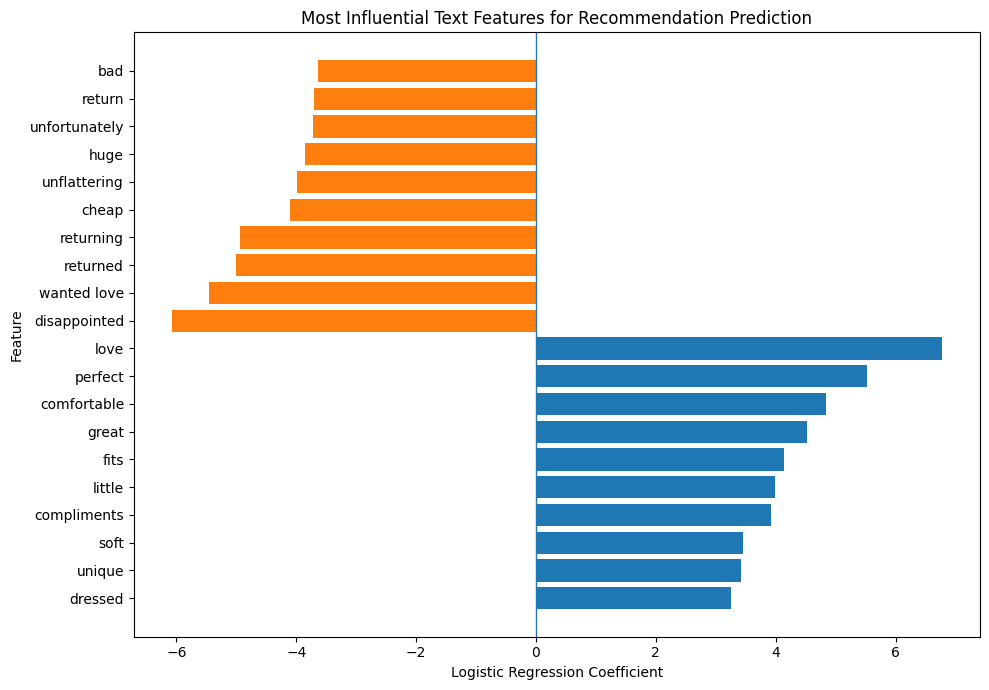

In [110]:
import matplotlib.pyplot as plt

# Select the strongest features from both classes
top_positive = top_positive_features.head(10).sort_values("Coefficient")
top_negative = top_negative_features.head(10).sort_values("Coefficient")

plt.figure(figsize=(10, 7))

plt.barh(
    top_positive["Feature"],
    top_positive["Coefficient"]
)

plt.barh(
    top_negative["Feature"],
    top_negative["Coefficient"]
)

plt.axvline(0, linewidth=1)

plt.title("Most Influential Text Features for Recommendation Prediction")
plt.xlabel("Logistic Regression Coefficient")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [111]:
# Check for potential target leakage in review text

leakage_terms = [
    "recommend",
    "recommended",
    "recommendation",
    "would recommend",
    "not recommend",
    "do not recommend",
    "did not recommend",
    "would not recommend",
    "rating",
    "star",
    "stars"
]

review_text_lower = cleaned_df["Review Text"].fillna("").str.lower()

print("Potential target-related terms found in review text:")
print("=" * 55)

for term in leakage_terms:
    count = review_text_lower.str.contains(
        term,
        regex=False
    ).sum()

    print(f"{term}: {count}")

Potential target-related terms found in review text:
recommend: 1094
recommended: 66
recommendation: 12
would recommend: 139
not recommend: 66
do not recommend: 19
did not recommend: 0
would not recommend: 32
rating: 56
star: 496
stars: 142


In [112]:
# Check the relationship between recommendation-related words and the target

recommendation_text_mask = review_text_lower.str.contains(
    "recommend",
    regex=False
)

leakage_check = pd.crosstab(
    recommendation_text_mask,
    cleaned_df["Recommended IND"],
    normalize="index"
) * 100

leakage_check.columns = [
    "Not Recommended (%)",
    "Recommended (%)"
]

print("Recommendation-related terms in review text:")
print(leakage_check.round(2))

Recommendation-related terms in review text:
             Not Recommended (%)  Recommended (%)
Review Text                                      
False                      18.15            81.85
True                       10.15            89.85


In [113]:
import re

# Remove potentially target-related terms from review text
leakage_patterns = [
    r"\bwould recommend\b",
    r"\bwould not recommend\b",
    r"\bdo not recommend\b",
    r"\bdid not recommend\b",
    r"\bnot recommend\b",
    r"\brecommendation\b",
    r"\brecommended\b",
    r"\brecommend\b",
    r"\brating\b",
    r"\bstars?\b"
]

def remove_leakage_terms(text):
    if pd.isna(text):
        return ""

    text = text.lower()

    for pattern in leakage_patterns:
        text = re.sub(pattern, "", text)

    return text

text_df["Clean Review Text"] = text_df["Review Text"].apply(
    remove_leakage_terms
)

print("Leakage-controlled text prepared.")
print("Number of reviews:", len(text_df))

Leakage-controlled text prepared.
Number of reviews: 22640


In [114]:
# Split the leakage-controlled review text
X_clean_text = text_df["Clean Review Text"]
y_clean_text = text_df["Recommended IND"]

X_train_clean, X_test_clean, y_train_clean, y_test_clean = train_test_split(
    X_clean_text,
    y_clean_text,
    test_size=0.2,
    random_state=42,
    stratify=y_clean_text
)

# Create TF-IDF features
tfidf_clean = TfidfVectorizer(
    max_features=5000,
    stop_words="english",
    ngram_range=(1, 2),
    min_df=3
)

X_train_clean_tfidf = tfidf_clean.fit_transform(X_train_clean)
X_test_clean_tfidf = tfidf_clean.transform(X_test_clean)

print("Training matrix shape:", X_train_clean_tfidf.shape)
print("Testing matrix shape:", X_test_clean_tfidf.shape)

Training matrix shape: (18112, 5000)
Testing matrix shape: (4528, 5000)


In [116]:
# Make predictions using the TF-IDF test matrix
y_pred_clean = clean_text_model.predict(X_test_clean_tfidf)

# Calculate evaluation metrics
clean_text_accuracy = accuracy_score(
    y_test_clean,
    y_pred_clean
)

clean_text_auc = roc_auc_score(
    y_test_clean,
    clean_text_model.predict_proba(X_test_clean_tfidf)[:, 1]
)

print(
    "Leakage-Controlled TF-IDF Accuracy:",
    round(clean_text_accuracy, 4)
)

print(
    "Leakage-Controlled TF-IDF ROC-AUC:",
    round(clean_text_auc, 4)
)

print("\nClassification Report:")
print(classification_report(y_test_clean, y_pred_clean))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_clean, y_pred_clean))

Leakage-Controlled TF-IDF Accuracy: 0.8598
Leakage-Controlled TF-IDF ROC-AUC: 0.9251

Classification Report:
              precision    recall  f1-score   support

           0       0.58      0.82      0.68       820
           1       0.96      0.87      0.91      3708

    accuracy                           0.86      4528
   macro avg       0.77      0.84      0.79      4528
weighted avg       0.89      0.86      0.87      4528


Confusion Matrix:
[[ 671  149]
 [ 486 3222]]


In [117]:
# Compare the main predictive models

model_comparison = pd.DataFrame({
    "Model": [
        "Structured Logistic Regression",
        "Original TF-IDF Logistic Regression",
        "Leakage-Controlled TF-IDF Logistic Regression"
    ],
    "Accuracy": [
        balanced_accuracy,
        text_accuracy,
        clean_text_accuracy
    ],
    "ROC-AUC": [
        np.nan,
        text_auc,
        clean_text_auc
    ],
    "Macro F1": [
        0.50,
        0.80,
        0.79
    ]
})

model_comparison = model_comparison.round(4)

print("Model Performance Comparison")
print("=" * 60)
model_comparison

Model Performance Comparison


,Model,Accuracy,ROC-AUC,Macro F1
0,Structured Logistic Regression,0.5881,NaN,0.50
1,Original TF-IDF Logistic Regression,0.8615,0.9255,0.80
2,Leakage-Controlled TF-IDF Logistic Regression,0.8598,0.9251,0.79
